# Smart Customer Churn & Retention Intelligence System

## Project Overview

Customer churn is one of the major challenges faced by subscription-based and service-oriented businesses. Losing existing customers can significantly impact revenue and profitability. Therefore, identifying customers who are likely to leave the company can help businesses take proactive retention actions.

This project develops a machine learning-based Customer Churn Prediction and Retention Intelligence System.

The project goes beyond traditional churn prediction by:

- Predicting the probability of customer churn
- Categorizing customers into risk groups
- Identifying financially valuable customers at risk
- Creating a customer priority score
- Recommending suitable retention actions

The final output can also be used to create an interactive business dashboard in Power BI.

## Business Objective

The objective of this project is to answer the following questions:

1. Which customers are most likely to churn?
2. What factors contribute to customer churn?
3. Which high-risk customers should the company prioritize?
4. What retention action should be recommended for each customer?
5. How much customer value is potentially at risk?

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Machine Learning
- Power BI

# 1. Import Required Libraries

In this section, we import the libraries required for:

- Data manipulation
- Numerical operations
- Data visualization
- Data preprocessing
- Machine learning model development
- Model evaluation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

# 2. Generate Customer Dataset

For this project, a synthetic customer dataset is created to simulate a subscription-based business.

The dataset contains information related to:

- Customer tenure
- Monthly charges
- Total customer spending
- Customer support tickets
- Late payments
- Monthly service usage
- Contract type

A churn probability is generated based on selected customer characteristics to simulate realistic customer behavior.

In [2]:
# Set random seed for reproducibility

np.random.seed(42)


# Number of customers

n = 1000


# Create customer dataset

data = pd.DataFrame({

    "customer_id": np.arange(1, n + 1),

    "tenure_months": np.random.randint(1,73,n ),

    "monthly_charges": np.random.randint( 300, 3001,n),

    "total_spend": np.random.randint(1000,100001,n),

    "support_tickets": np.random.randint(0,11,n),

    "late_payments": np.random.randint( 0,7, n),

    "monthly_usage_hours": np.random.randint( 1,201, n ),

    "contract_type": np.random.choice(
        [
            "Monthly",
            "Yearly",
            "Two Year"
        ],
        size=n,
        p=[
            0.50,
            0.30,
            0.20
        ]
    )

})


data.head()

,customer_id,tenure_months,monthly_charges,total_spend,support_tickets,late_payments,monthly_usage_hours,contract_type
0,1,52,1132,39067,2,2,48,Two Year
1,2,15,612,43685,3,2,18,Two Year
2,3,72,2158,19073,7,1,144,Yearly
3,4,61,2307,37035,0,3,183,Yearly
4,5,21,2306,65977,5,3,39,Monthly


# 3. Create Customer Churn Target Variable

The churn variable represents whether a customer has left the company.

- 1 = Customer churned
- 0 = Customer did not churn

Churn probability is influenced by selected risk factors such as:

- Short customer tenure
- High number of support tickets
- Frequent late payments
- Monthly contract type

Customers with higher spending receive a lower churn probability because high-value customers may demonstrate stronger engagement with the business.

In [3]:
# Create churn probability

churn_probability = (

    0.10

    + (data["tenure_months"] < 12) * 0.20

    + (data["support_tickets"] > 5) * 0.20

    + (data["late_payments"] > 2) * 0.15

    + (data["contract_type"] == "Monthly") * 0.15

    - (data["total_spend"] > 50000) * 0.10
)


# Ensure probabilities remain between valid limits

churn_probability = np.clip(
    churn_probability,
    0.02,
    0.95
)


# Generate churn variable

data["churn"] = np.random.binomial(
    n=1,
    p=churn_probability
)


data.head()

,customer_id,tenure_months,monthly_charges,total_spend,support_tickets,late_payments,monthly_usage_hours,contract_type,churn
0,1,52,1132,39067,2,2,48,Two Year,0
1,2,15,612,43685,3,2,18,Two Year,0
2,3,72,2158,19073,7,1,144,Yearly,0
3,4,61,2307,37035,0,3,183,Yearly,1
4,5,21,2306,65977,5,3,39,Monthly,0


# 4. Basic Data Exploration

Before building machine learning models, it is important to understand the structure and quality of the dataset.

The following checks are performed:

- Dataset dimensions
- Data types
- Missing values
- Statistical summary
- Churn distribution

In [5]:
print("Dataset Shape:")

print(data.shape)


print("\nData Types:")

print(data.dtypes)


print("\nMissing Values:")

print(data.isnull().sum())

Dataset Shape:
(1000, 9)

Data Types:
customer_id             int64
tenure_months           int32
monthly_charges         int32
total_spend             int32
support_tickets         int32
late_payments           int32
monthly_usage_hours     int32
contract_type          object
churn                   int32
dtype: object

Missing Values:
customer_id            0
tenure_months          0
monthly_charges        0
total_spend            0
support_tickets        0
late_payments          0
monthly_usage_hours    0
contract_type          0
churn                  0
dtype: int64


In [6]:
data.describe()

,customer_id,tenure_months,monthly_charges,total_spend,support_tickets,late_payments,monthly_usage_hours,churn
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,35.881000,1606.36400,49896.049000,4.926000,3.031000,104.847000,0.313000
std,288.819436,20.958915,775.18298,28825.223852,3.180981,2.001011,58.071214,0.463946
min,1.000000,1.000000,301.00000,1155.000000,0.000000,0.000000,1.000000,0.000000
25%,250.750000,17.750000,970.00000,24690.750000,2.000000,1.000000,55.000000,0.000000
50%,500.500000,35.500000,1588.50000,50152.000000,5.000000,3.000000,107.500000,0.000000
75%,750.250000,54.000000,2285.25000,74805.500000,8.000000,5.000000,155.000000,1.000000
max,1000.000000,72.000000,2995.00000,99989.000000,10.000000,6.000000,200.000000,1.000000


# 5. Customer Churn Distribution

This analysis examines the distribution between customers who churned and customers who remained with the company.

Understanding class distribution is important because machine learning models can be affected when one class is significantly larger than the other.

In [7]:
churn_counts = data["churn"].value_counts()


print("Churn Distribution:")

print(churn_counts)


print("\nChurn Percentage:")

print(
    data["churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Churn Distribution:
churn
0    687
1    313
Name: count, dtype: int64

Churn Percentage:
churn
0    68.7
1    31.3
Name: proportion, dtype: float64


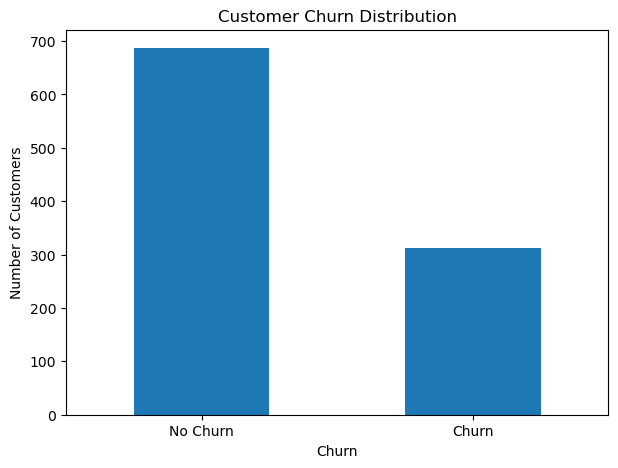

In [8]:
plt.figure(figsize=(7, 5))

data["churn"].value_counts().plot(
    kind="bar"
)

plt.title("Customer Churn Distribution")

plt.xlabel("Churn")

plt.ylabel("Number of Customers")

plt.xticks(
    ticks=[0, 1],
    labels=[
        "No Churn",
        "Churn"
    ],
    rotation=0
)

plt.show()

# 6. Prepare Data for Machine Learning

The customer ID column is removed because it is only an identifier and does not provide meaningful predictive information.

The dataset is divided into:

- Features (X)
- Target Variable (y)

The data is then split into training and testing datasets.

The training dataset is used to train the machine learning models, while the testing dataset is used to evaluate model performance.

In [9]:
# Define features

X = data.drop(
    columns=[
        "customer_id",
        "churn"
    ]
)


# Define target variable

y = data["churn"]


print("Feature Dataset Shape:")

print(X.shape)


print("\nTarget Variable Shape:")

print(y.shape)

Feature Dataset Shape:
(1000, 7)

Target Variable Shape:
(1000,)


# 7. Define Numerical and Categorical Features

Machine learning algorithms require data to be properly prepared.

Numerical variables are standardized for Logistic Regression, while categorical variables are converted into numerical format using One-Hot Encoding.

One-Hot Encoding is used for the contract type variable.

The `handle_unknown="ignore"` parameter ensures that the model does not produce an error if an unexpected category appears during prediction.

In [10]:
numerical_features = [

    "tenure_months",

    "monthly_charges",

    "total_spend",

    "support_tickets",

    "late_payments",

    "monthly_usage_hours"
]


categorical_features = [

    "contract_type"
]

In [11]:
# Create preprocessing pipeline

preprocessor = ColumnTransformer(

    transformers=[

        (
            "numerical",

            StandardScaler(),

            numerical_features
        ),

        (
            "categorical",

            OneHotEncoder(
                handle_unknown="ignore"
            ),

            categorical_features
        )

    ]
)

# 8. Split Data into Training and Testing Sets

The dataset is divided into:

- 80% Training Data
- 20% Testing Data

Stratified sampling is used to maintain the proportion of churn and non-churn customers in both datasets.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)


print("Training Data Shape:")

print(X_train.shape)


print("\nTesting Data Shape:")

print(X_test.shape)

Training Data Shape:
(800, 7)

Testing Data Shape:
(200, 7)


# 9. Logistic Regression Model

Logistic Regression is used as the baseline machine learning model.

It is particularly useful for binary classification problems where the target variable has two possible outcomes.

In this project:

- 0 represents a customer who does not churn
- 1 represents a customer who churns

In [13]:
logistic_model = Pipeline(

    steps=[

        (
            "preprocessor",

            preprocessor
        ),

        (
            "model",

            LogisticRegression(

                max_iter=2000,

                random_state=42
            )
        )

    ]
)

In [14]:
# Train Logistic Regression model

logistic_model.fit(

    X_train,

    y_train
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [15]:
# Generate predictions

logistic_predictions = logistic_model.predict(
    X_test
)


# Generate churn probabilities

logistic_probabilities = logistic_model.predict_proba(
    X_test
)[:, 1]

# 10. Evaluate Logistic Regression Model

The model is evaluated using multiple performance metrics:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC Score

Using multiple evaluation metrics provides a better understanding of model performance than accuracy alone.

In [16]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)


logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    zero_division=0
)


logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    zero_division=0
)


logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    zero_division=0
)


logistic_auc = roc_auc_score(
    y_test,
    logistic_probabilities
)


print("Logistic Regression Performance")

print("-" * 35)

print(
    "Accuracy:",
    round(logistic_accuracy, 4)
)

print(
    "Precision:",
    round(logistic_precision, 4)
)

print(
    "Recall:",
    round(logistic_recall, 4)
)

print(
    "F1 Score:",
    round(logistic_f1, 4)
)

print(
    "ROC-AUC Score:",
    round(logistic_auc, 4)
)

Logistic Regression Performance
-----------------------------------
Accuracy: 0.685
Precision: 0.5
Recall: 0.1905
F1 Score: 0.2759
ROC-AUC Score: 0.6201


# 11. Random Forest Model

Random Forest is an ensemble machine learning algorithm that creates multiple decision trees and combines their predictions.

Random Forest can capture more complex and non-linear relationships between customer characteristics and churn behavior.

The model is compared with Logistic Regression to identify which model performs better.

In [17]:
random_forest_model = Pipeline(

    steps=[

        (
            "preprocessor",

            preprocessor
        ),

        (
            "model",

            RandomForestClassifier(

                n_estimators=300,

                random_state=42,

                class_weight="balanced",

                n_jobs=-1
            )
        )

    ]
)

In [18]:
# Train Random Forest model

random_forest_model.fit(

    X_train,

    y_train
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [19]:
# Generate predictions

rf_predictions = random_forest_model.predict(
    X_test
)


# Generate churn probabilities

rf_probabilities = random_forest_model.predict_proba(
    X_test
)[:, 1]

# 12. Evaluate Random Forest Model

The Random Forest model is evaluated using the same performance metrics as Logistic Regression.

The model comparison helps determine which algorithm is more suitable for predicting customer churn.

In [20]:
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)


rf_precision = precision_score(
    y_test,
    rf_predictions,
    zero_division=0
)


rf_recall = recall_score(
    y_test,
    rf_predictions,
    zero_division=0
)


rf_f1 = f1_score(
    y_test,
    rf_predictions,
    zero_division=0
)


rf_auc = roc_auc_score(
    y_test,
    rf_probabilities
)


print("Random Forest Performance")

print("-" * 35)

print(
    "Accuracy:",
    round(rf_accuracy, 4)
)

print(
    "Precision:",
    round(rf_precision, 4)
)

print(
    "Recall:",
    round(rf_recall, 4)
)

print(
    "F1 Score:",
    round(rf_f1, 4)
)

print(
    "ROC-AUC Score:",
    round(rf_auc, 4)
)

Random Forest Performance
-----------------------------------
Accuracy: 0.69
Precision: 0.5172
Recall: 0.2381
F1 Score: 0.3261
ROC-AUC Score: 0.5937


# 13. Model Comparison

Both models are compared using multiple evaluation metrics.

For this project, the model with the higher ROC-AUC score will be selected as the final model.

ROC-AUC is useful because the project requires churn probabilities for customer risk prioritization.

In [21]:
model_comparison = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "Random Forest"
    ],

    "Accuracy": [

        logistic_accuracy,

        rf_accuracy
    ],

    "Precision": [

        logistic_precision,

        rf_precision
    ],

    "Recall": [

        logistic_recall,

        rf_recall
    ],

    "F1 Score": [

        logistic_f1,

        rf_f1
    ],

    "ROC-AUC": [

        logistic_auc,

        rf_auc
    ]

})


model_comparison = model_comparison.round(4)


model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.685,0.5000,0.1905,0.2759,0.6201
1,Random Forest,0.690,0.5172,0.2381,0.3261,0.5937


In [22]:
if rf_auc >= logistic_auc:

    best_model = random_forest_model

    best_model_name = "Random Forest"

else:

    best_model = logistic_model

    best_model_name = "Logistic Regression"


print("Selected Model:")

print(best_model_name)

Selected Model:
Logistic Regression


# 15. Generate Churn Probability for All Customers

The selected machine learning model is used to generate churn probabilities for all customers.

A churn probability closer to:

- 1 indicates higher churn risk
- 0 indicates lower churn risk

In [24]:
data["churn_probability"] = best_model.predict_proba(
    X
)[:, 1]


# Convert probability into percentage

data["churn_probability_percentage"] = (

    data["churn_probability"]

    * 100

).round(2)


data[
    [

        "customer_id",

        "churn_probability",

        "churn_probability_percentage"

    ]

].head()

,customer_id,churn_probability,churn_probability_percentage
0,1,0.126092,12.61
1,2,0.172432,17.24
2,3,0.174232,17.42
3,4,0.141054,14.11
4,5,0.345241,34.52


# 16. Customer Risk Categorization

Customers are divided into three risk categories based on their predicted churn probability.

- High Risk: Churn probability of 75% or above
- Medium Risk: Churn probability between 50% and 75%
- Low Risk: Churn probability below 50%

This classification makes the machine learning output easier for business stakeholders to interpret.

In [26]:
def risk_category(probability):

    if probability >= 0.75:

        return "High Risk"

    elif probability >= 0.50:

        return "Medium Risk"

    else:

        return "Low Risk"

In [27]:
data["risk_category"] = data[
    "churn_probability"
].apply(
    risk_category
)


data[
    [

        "customer_id",

        "churn_probability_percentage",

        "risk_category"

    ]

].head()

,customer_id,churn_probability_percentage,risk_category
0,1,12.61,Low Risk
1,2,17.24,Low Risk
2,3,17.42,Low Risk
3,4,14.11,Low Risk
4,5,34.52,Low Risk


# 17. Generate Retention Recommendations

The project does not stop at churn prediction.

A rule-based recommendation system is used to suggest possible retention actions based on customer risk and behavior.

Examples include:

- Priority customer support
- Flexible payment plans
- Personalized retention offers
- Engagement campaigns

This converts machine learning predictions into actionable business insights.

In [29]:
def recommend_action(row):

    if (

        row["risk_category"] == "High Risk"

        and row["support_tickets"] > 5

    ):

        return "Priority Customer Support"


    elif (

        row["risk_category"] == "High Risk"

        and row["late_payments"] > 2

    ):

        return "Flexible Payment Plan"


    elif row["risk_category"] == "High Risk":

        return "Personalized Retention Offer"


    elif row["risk_category"] == "Medium Risk":

        return "Discount or Engagement Campaign"


    else:

        return "No Immediate Action"

In [30]:
data["recommended_action"] = data.apply(

    recommend_action,

    axis=1
)


data[
    [

        "customer_id",

        "risk_category",

        "recommended_action"

    ]

].head(10)

,customer_id,risk_category,recommended_action
0,1,Low Risk,No Immediate Action
1,2,Low Risk,No Immediate Action
2,3,Low Risk,No Immediate Action
3,4,Low Risk,No Immediate Action
4,5,Low Risk,No Immediate Action
5,6,Low Risk,No Immediate Action
6,7,Low Risk,No Immediate Action
7,8,Low Risk,No Immediate Action
8,9,Low Risk,No Immediate Action
9,10,Low Risk,No Immediate Action


# 18. Create Customer Priority Score

Not all customers should receive the same level of retention effort.

A priority score is created by combining:

- Probability of churn
- Customer financial value

Priority Score = Churn Probability × Total Customer Spend

Customers with a high priority score are both:

- More likely to churn
- Financially valuable to the business

These customers should receive immediate attention from the retention team.

In [32]:
data["priority_score"] = (

    data["churn_probability"]

    * data["total_spend"]

).round(2)

# 19. Calculate Estimated Customer Value at Risk

Estimated customer value at risk is calculated by multiplying total customer spending by predicted churn probability.

This provides a business-oriented estimate of potential value that could be affected by customer churn.

In [33]:
data["estimated_value_at_risk"] = (

    data["total_spend"]

    * data["churn_probability"]

).round(2)

# 20. Identify Priority Customers

Customers are ranked based on their priority score.

The customers at the top of the list represent high-value customers with a high predicted risk of churn.

In [34]:
priority_customers = data.sort_values(

    by="priority_score",

    ascending=False
)


priority_customers[

    [

        "customer_id",

        "churn_probability_percentage",

        "total_spend",

        "priority_score",

        "estimated_value_at_risk",

        "risk_category",

        "recommended_action"

    ]

].head(20)

,customer_id,churn_probability_percentage,total_spend,priority_score,estimated_value_at_risk,risk_category,recommended_action
108,109,56.73,98359,55803.43,55803.43,Medium Risk,Discount or Engagement Campaign
673,674,60.34,89664,54106.41,54106.41,Medium Risk,Discount or Engagement Campaign
832,833,52.66,99696,52498.55,52498.55,Medium Risk,Discount or Engagement Campaign
624,625,54.62,94269,51491.28,51491.28,Medium Risk,Discount or Engagement Campaign
948,949,51.31,99646,51129.98,51129.98,Medium Risk,Discount or Engagement Campaign
795,796,64.57,77637,50130.64,50130.64,Medium Risk,Discount or Engagement Campaign
293,294,51.70,93949,48567.88,48567.88,Medium Risk,Discount or Engagement Campaign
472,473,56.69,84930,48150.59,48150.59,Medium Risk,Discount or Engagement Campaign
798,799,62.25,75658,47096.08,47096.08,Medium Risk,Discount or Engagement Campaign
787,788,55.23,85246,47079.39,47079.39,Medium Risk,Discount or Engagement Campaign


# 21. Feature Importance Analysis

Feature importance helps identify which variables have the greatest influence on the machine learning model.

This analysis is particularly useful for understanding the drivers of customer churn.

Feature importance is extracted when Random Forest is selected as the final model.

In [36]:
if best_model_name == "Random Forest":

    fitted_preprocessor = best_model.named_steps[
        "preprocessor"
    ]

    fitted_random_forest = best_model.named_steps[
        "model"
    ]


    feature_names = fitted_preprocessor.get_feature_names_out()


    feature_importance = pd.DataFrame({

        "Feature": feature_names,

        "Importance": fitted_random_forest.feature_importances_

    })


    feature_importance = feature_importance.sort_values(

        by="Importance",

        ascending=False
    )


    feature_importance.head(10)

# 22. Visualize Feature Importance

The chart below displays the most influential features used by the Random Forest model to predict customer churn.

This helps convert the machine learning model into interpretable business insights.

In [37]:
if best_model_name == "Random Forest":

    top_features = feature_importance.head(10)


    plt.figure(figsize=(10, 6))


    plt.barh(

        top_features["Feature"],

        top_features["Importance"]
    )


    plt.xlabel("Importance")

    plt.ylabel("Feature")

    plt.title("Top 10 Feature Importance")


    plt.gca().invert_yaxis()


    plt.show()

# 23. Confusion Matrix

A confusion matrix is used to evaluate how accurately the selected machine learning model classifies churn and non-churn customers.

It displays:

- True Positives
- True Negatives
- False Positives
- False Negatives

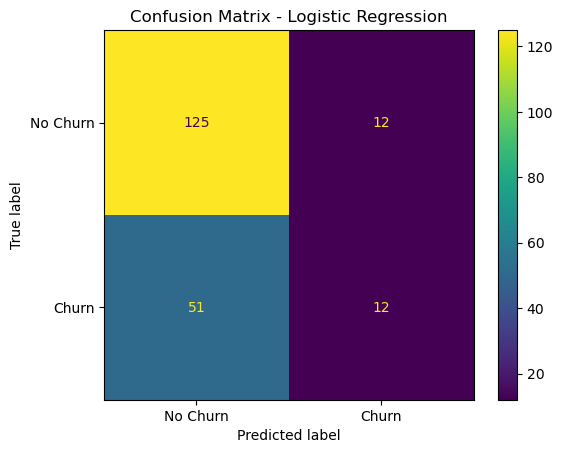

In [38]:
best_predictions = best_model.predict(
    X_test
)


cm = confusion_matrix(

    y_test,

    best_predictions
)


display = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=[
        "No Churn",
        "Churn"
    ]
)


display.plot()


plt.title(
    f"Confusion Matrix - {best_model_name}"
)


plt.show()

# 24. Risk Category Analysis

This analysis shows the number of customers belonging to each churn risk category.

The results can help management understand the overall customer risk profile.

In [39]:
risk_summary = data[
    "risk_category"
].value_counts()


print(risk_summary)

risk_category
Low Risk       884
Medium Risk    116
Name: count, dtype: int64


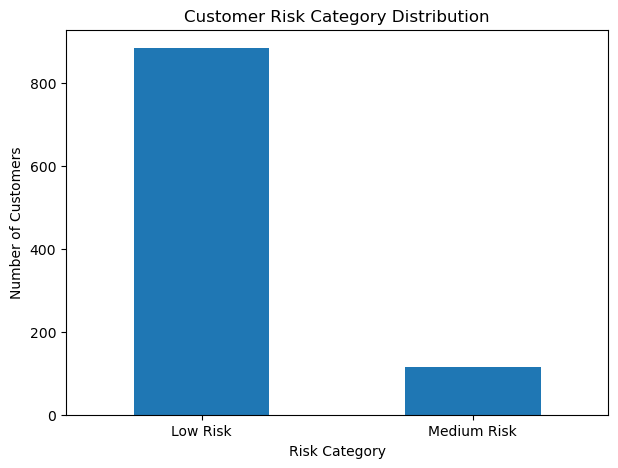

In [40]:
plt.figure(figsize=(7, 5))


data["risk_category"].value_counts().plot(
    kind="bar"
)


plt.title(
    "Customer Risk Category Distribution"
)


plt.xlabel(
    "Risk Category"
)


plt.ylabel(
    "Number of Customers"
)


plt.xticks(
    rotation=0
)


plt.show()

# 25. Business Summary

The final dataset contains machine learning predictions and business intelligence outputs.

The following information is available for each customer:

- Predicted churn probability
- Churn risk category
- Recommended retention action
- Customer priority score
- Estimated customer value at risk

This information can be used by business stakeholders to prioritize customer retention strategies.

In [41]:
total_customers = len(data)


high_risk_customers = len(

    data[
        data["risk_category"] == "High Risk"
    ]

)


average_churn_probability = (

    data["churn_probability"]

    .mean()

    * 100
)


total_value_at_risk = (

    data["estimated_value_at_risk"]

    .sum()
)


print(
    "Total Customers:",
    total_customers
)


print(
    "High-Risk Customers:",
    high_risk_customers
)


print(
    "Average Churn Probability:",
    round(
        average_churn_probability,
        2
    ),
    "%"
)


print(
    "Estimated Total Value at Risk:",
    round(
        total_value_at_risk,
        2
    )
)

Total Customers: 1000
High-Risk Customers: 0
Average Churn Probability: 31.24 %
Estimated Total Value at Risk: 14711359.13


# 26. Export Final Dataset

The final dataset is exported as a CSV file.

This file can be imported into Power BI to create an interactive dashboard for customer churn and retention analysis.

In [42]:
data.to_csv(

    "customer_churn_predictions.csv",

    index=False
)


print(
    "File successfully exported as customer_churn_predictions.csv"
)

File successfully exported as customer_churn_predictions.csv


# Conclusion

This project developed a Smart Customer Churn and Retention Intelligence System using machine learning.

Two machine learning models, Logistic Regression and Random Forest, were developed and compared using multiple performance metrics. The best-performing model was selected based on ROC-AUC performance.

The selected model was then used to generate churn probabilities for individual customers.

The project extended beyond traditional churn prediction by introducing:

- Customer risk categorization
- Retention recommendations
- Customer priority scoring
- Estimated customer value at risk

The final output helps businesses move from predictive analytics to actionable decision-making.

Instead of simply identifying customers who may churn, the system helps answer the more important business question:

**Which customers should the company prioritize, and what action should be taken to retain them?**